# Tugas Kelompok 3: Analisis Deskriptif Keamanan dan Kebersihan Pangan Program MBG

**Topik:** kekhawatiran publik terhadap keamanan dan kebersihan pangan Program Makan Bergizi Gratis (MBG) di YouTube dan X.

Notebook ini menghasilkan *descriptive analytics* untuk Bab 4 laporan TK3, sesuai ukuran yang dijelaskan pada Subbab 3.3 (Analisis Deskriptif):

| No. | Ukuran | Data |
|---|---|---|
| 1 | Karakteristik dataset: jumlah dokumen per platform dan jenis konten, sebelum dan sesudah penyaringan; jumlah penulis dan konteks | Seluruh dataset |
| 2 | Pola temporal: volume per minggu, serta menurut hari dan jam (WIB) | Dokumen relevan dan layak pakai |
| 3 | Karakteristik konten: kata tunggal dan pasangan kata yang paling sering muncul | Dokumen `rq1_eligible` selain video |
| 4 | Pola interaksi: median, persentil ke-90 dan ke-99 jumlah suka, serta proporsi dokumen tanpa suka | Dokumen relevan dan layak pakai selain video |

**Input:** `data/processed/mbg_processed/mbg_processed.csv` (unduh dari Google Drive, lihat README).

**Output:** folder `analysis/deskriptif/hasil/` berisi tabel (`.csv`), grafik (`figures/*.png`), dan `ringkasan_deskriptif.json` berisi angka utama untuk laporan.

# 1. Persiapan

In [13]:
import json
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight"})

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
DATA_PATH = ROOT / "data/processed/mbg_processed/mbg_processed.csv"
OUT = ROOT / "analysis/deskriptif/hasil"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

PLATFORM_LABEL = {"youtube": "YouTube", "x": "X"}
PLATFORM_COLOR = {"YouTube": "#c0392b", "X": "#2c3e50"}
TOP_N = 20
RINGKASAN = {}  # angka utama yang dipakai di laporan


def savefig(name):
    plt.savefig(FIG / name)
    plt.show()


def to_bool(s):
    # CSV menyimpan boolean sebagai teks; nilai kosong dianggap False
    return s.map({True: True, False: False, "True": True, "False": False,
                  "true": True, "false": False}).fillna(False).astype(bool)

# 2. Memuat Data

Hanya kolom yang dibutuhkan yang dimuat agar hemat memori. Waktu terbit dikonversi dari UTC ke WIB (Asia/Jakarta).

In [14]:
COLS = [
    "doc_id", "platform", "doc_type", "context_id", "author_hash", "published_at_utc",
    "like_count", "common_is_usable", "is_relevant_candidate", "rq1_eligible", "rq1_text_light",
]
df = pd.read_csv(DATA_PATH, usecols=COLS, low_memory=False)
for c in ["common_is_usable", "is_relevant_candidate", "rq1_eligible"]:
    df[c] = to_bool(df[c])
df["platform"] = df["platform"].map(PLATFORM_LABEL).fillna(df["platform"])
df["like_count"] = pd.to_numeric(df["like_count"], errors="coerce").fillna(0).astype(int)
df["waktu_wib"] = pd.to_datetime(df["published_at_utc"], utc=True, errors="coerce").dt.tz_convert("Asia/Jakarta")

usable = df[df["common_is_usable"]]
relevan = usable[usable["is_relevant_candidate"]]
print(f"Seluruh dataset     : {len(df):,}")
print(f"Layak pakai         : {len(usable):,}")
print(f"Relevan dan layak   : {len(relevan):,}")
print("Rentang waktu (WIB) :", df["waktu_wib"].min(), "s.d.", df["waktu_wib"].max())

Seluruh dataset     : 1,109,888
Layak pakai         : 1,001,029
Relevan dan layak   : 99,623
Rentang waktu (WIB) : 2025-01-01 14:56:38+07:00 s.d. 2026-10-24 07:55:09+07:00


# 3. Karakteristik Dataset

Jumlah dokumen per platform dan jenis konten pada tiga tahap: seluruh dataset, setelah penyaringan kelayakan (`common_is_usable`), dan setelah penyaringan relevansi (`is_relevant_candidate`). Jumlah penulis unik dan konteks percakapan (video atau utas) juga dihitung karena konsentrasi dokumen pada sedikit konteks memengaruhi cara membaca pola di bab berikutnya.

In [15]:
def hitung(d, tahap):
    return d.groupby(["platform", "doc_type"]).size().rename(tahap)

tabel_tahap = pd.concat([
    hitung(df, "seluruh"), hitung(usable, "layak_pakai"), hitung(relevan, "relevan"),
], axis=1).fillna(0).astype(int)
tabel_tahap.loc[("Total", ""), :] = tabel_tahap.sum()
tabel_tahap["persen_relevan_dari_seluruh"] = (100 * tabel_tahap["relevan"] / tabel_tahap["seluruh"]).round(2)
tabel_tahap.to_csv(OUT / "01_jumlah_dokumen_per_tahap.csv")
display(tabel_tahap)

seluruh  layak_pakai  relevan  persen_relevan_dari_seluruh
platform doc_type                                                              
X        post        13985.0      13649.0   7170.0                        51.27
         quote        2481.0       2471.0   1817.0                        73.24
         reply        8069.0       7941.0   5521.0                        68.42
YouTube  comment    892141.0     808820.0  71958.0                         8.07
         reply      175549.0     150485.0   8470.0                         4.82
         video       17663.0      17663.0   4687.0                        26.54
Total              1109888.0    1001029.0  99623.0                         8.98

In [16]:
nonvideo_rel = relevan[relevan["doc_type"] != "video"]
profil = nonvideo_rel.groupby("platform").agg(
    dokumen=("doc_id", "size"),
    penulis_unik=("author_hash", "nunique"),
    konteks_unik=("context_id", "nunique"),
)
profil["dokumen_per_penulis"] = (profil["dokumen"] / profil["penulis_unik"]).round(2)
profil["dokumen_per_konteks"] = (profil["dokumen"] / profil["konteks_unik"]).round(2)

# Porsi dokumen yang berasal dari 10 konteks (video/utas) terbanyak
top10 = (nonvideo_rel.groupby(["platform", "context_id"]).size()
         .groupby(level=0, group_keys=False).nlargest(10).groupby(level=0).sum())
profil["persen_dari_10_konteks_teratas"] = (100 * top10 / profil["dokumen"]).round(1)

# Porsi dokumen dari 1% penulis paling aktif
def porsi_top_penulis(g, q=0.01):
    n = g["author_hash"].value_counts()
    k = max(1, int(np.ceil(len(n) * q)))
    return 100 * n.iloc[:k].sum() / n.sum()

profil["persen_dari_1pct_penulis_teraktif"] = (
    nonvideo_rel.dropna(subset=["author_hash"]).groupby("platform").apply(porsi_top_penulis).round(1)
)
profil.to_csv(OUT / "02_profil_penulis_konteks.csv")
display(profil)

RINGKASAN["tahap"] = {
    "seluruh": int(len(df)), "layak_pakai": int(len(usable)), "relevan": int(len(relevan)),
    "relevan_per_platform": relevan["platform"].value_counts().to_dict(),
    "persen_youtube_dari_relevan": round(100 * (relevan["platform"] == "YouTube").mean(), 2),
}
RINGKASAN["profil_nonvideo_relevan"] = profil.reset_index().to_dict(orient="records")

,dokumen,penulis_unik,konteks_unik,dokumen_per_penulis,dokumen_per_konteks,persen_dari_10_konteks_teratas,persen_dari_1pct_penulis_teraktif
platform,,,,,,,
X,14508,5902,13321,2.46,1.09,0.5,27.2
YouTube,80428,50895,7137,1.58,11.27,12.3,10.5


# 4. Pola Temporal

Volume dokumen relevan per minggu (WIB). Kedua platform digambar pada panel terpisah karena volumenya berbeda jauh. Garis putus-putus menandai akhir periode data X (30 September 2026), sehingga penurunan setelahnya bukan penurunan percakapan.

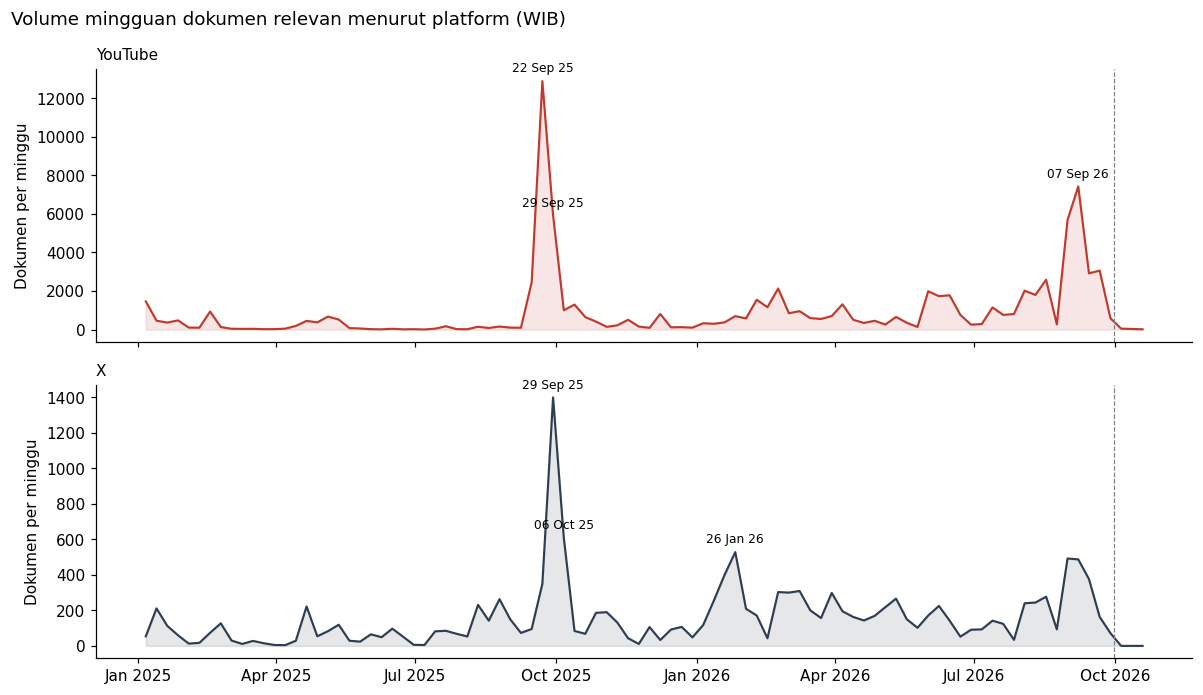

In [17]:
rel_t = relevan.dropna(subset=["waktu_wib"]).copy()
rel_t["minggu"] = rel_t["waktu_wib"].dt.tz_localize(None).dt.to_period("W-SUN").dt.start_time
mingguan = rel_t.groupby(["minggu", "platform"]).size().unstack(fill_value=0)
mingguan.to_csv(OUT / "03_volume_mingguan.csv")

AKHIR_X = rel_t.loc[rel_t["platform"] == "X", "waktu_wib"].max()
platforms = [p for p in ["YouTube", "X"] if p in mingguan.columns]

fig, axes = plt.subplots(len(platforms), 1, figsize=(11, 3.2 * len(platforms)), sharex=True)
axes = np.atleast_1d(axes)
puncak_semua = []
for ax, p in zip(axes, platforms):
    s = mingguan[p]
    ax.plot(s.index, s.values, color=PLATFORM_COLOR[p], lw=1.4)
    ax.fill_between(s.index, s.values, color=PLATFORM_COLOR[p], alpha=0.12)
    for tgl, val in s.nlargest(3).items():
        ax.annotate(tgl.strftime("%d %b %y"), (tgl, val), textcoords="offset points", xytext=(0, 6),
                    ha="center", fontsize=8)
        puncak_semua.append({"platform": p, "minggu_mulai": tgl.date().isoformat(), "dokumen": int(val)})
    if pd.notna(AKHIR_X):
        ax.axvline(AKHIR_X.tz_localize(None), ls="--", lw=0.8, color="grey")
    ax.set_ylabel("Dokumen per minggu")
    ax.set_title(p, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle("Volume mingguan dokumen relevan menurut platform (WIB)", x=0.01, ha="left")
fig.tight_layout()
savefig("01_volume_mingguan.png")

Untuk memahami puncak, setiap minggu puncak dicocokkan dengan konteks (video atau utas) yang paling banyak menyumbang dokumen pada minggu itu. Judul/teks konteks diambil dari baris dokumen induknya (`context_id` merujuk ke `doc_id` video atau unggahan awal).

In [18]:
# Ambil teks konteks secara bertahap (chunk) agar tidak memuat seluruh kolom teks ke memori
ctx_needed = set()
for row in puncak_semua:
    awal = pd.Timestamp(row["minggu_mulai"])
    sel = rel_t[(rel_t["platform"] == row["platform"]) & (rel_t["minggu"] == awal)]
    vc = sel["context_id"].value_counts()
    row["konteks_teratas"] = vc.index[0] if len(vc) else None
    row["persen_dari_konteks_teratas"] = round(100 * vc.iloc[0] / len(sel), 1) if len(vc) else None
    ctx_needed.update(vc.index[:1])

ctx_text = {}
for chunk in pd.read_csv(DATA_PATH, usecols=["doc_id", "text_clean"], chunksize=200_000):
    hit = chunk[chunk["doc_id"].isin(ctx_needed)]
    ctx_text.update(dict(zip(hit["doc_id"], hit["text_clean"].astype(str).str.slice(0, 160))))

tabel_puncak = pd.DataFrame(puncak_semua)
tabel_puncak["teks_konteks"] = tabel_puncak["konteks_teratas"].map(ctx_text)
tabel_puncak.to_csv(OUT / "04_minggu_puncak.csv", index=False)
display(tabel_puncak)
RINGKASAN["minggu_puncak"] = tabel_puncak.to_dict(orient="records")

,platform,minggu_mulai,dokumen,konteks_teratas,persen_dari_konteks_teratas,teks_konteks
0,YouTube,2025-09-22,12887,yt_v_u_Cdk9o0oqE,5.8,"Memohon ke DPR, JPPI Desak Program MBG Prabowo Disetop: Petaka bagi Pendidikan, Guru Tumbal Racun Download aplikasi ..."
1,YouTube,2026-09-07,7421,yt_v_Ez3Q849Wvcc,5.0,Dokter Ungkap Tiga Pemicu Gangguan Ingatan Usai Diduga Keracunan MBG #BeritasatuSiang Siswi korban dugaan keracunan ...
2,YouTube,2025-09-29,5926,yt_v_su5lLEvlC4A,4.1,"Lagi, Keracunan Massal Usai Santap MBG! Pemkab Garut Tetapkan Status KLB | Liputan 6 Tak sesuai namanya, alih-alih m..."
3,X,2025-09-29,1399,x_1973582078181777461,0.4,NaN
4,X,2025-10-06,609,x_1975454563395358776,1.1,NaN
5,X,2026-01-26,528,x_2016748946555887806,1.5,NaN


Distribusi menurut hari dan jam (WIB), dinyatakan sebagai persentase dari total dokumen relevan per platform, agar kedua platform dapat dibandingkan meskipun volumenya berbeda.

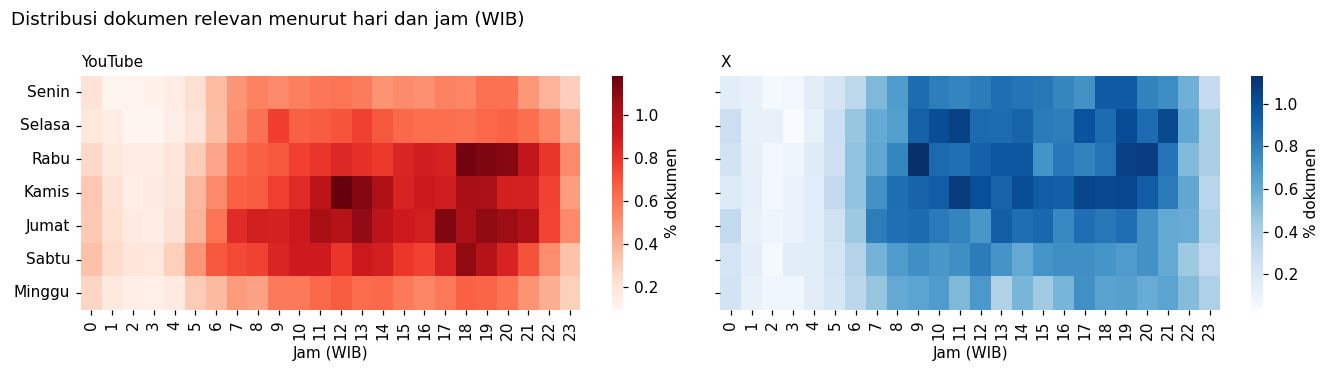

{
  "YouTube": {
    "jam_teramai": 19,
    "persen_jam_06_18": 61.0,
    "persen_hari_kerja": 72.9
  },
  "X": {
    "jam_teramai": 19,
    "persen_jam_06_18": 63.9,
    "persen_hari_kerja": 76.6
  }
}


In [19]:
HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
rel_t["hari"] = rel_t["waktu_wib"].dt.dayofweek
rel_t["jam"] = rel_t["waktu_wib"].dt.hour

fig, axes = plt.subplots(1, len(platforms), figsize=(6.2 * len(platforms), 3.4), sharey=True)
axes = np.atleast_1d(axes)
jam_puncak = {}
for ax, p in zip(axes, platforms):
    sub = rel_t[rel_t["platform"] == p]
    m = (sub.groupby(["hari", "jam"]).size().unstack(fill_value=0)
         .reindex(index=range(7), columns=range(24), fill_value=0))
    m = 100 * m / m.values.sum()
    sns.heatmap(m, ax=ax, cmap="Reds" if p == "YouTube" else "Blues", cbar_kws={"label": "% dokumen"})
    ax.set_yticklabels(HARI, rotation=0)
    ax.set_xlabel("Jam (WIB)")
    ax.set_ylabel("")
    ax.set_title(p, loc="left", fontsize=10)
    per_jam = sub["jam"].value_counts(normalize=True).sort_index()
    jam_puncak[p] = {
        "jam_teramai": int(per_jam.idxmax()),
        "persen_jam_06_18": round(100 * per_jam.loc[6:17].sum(), 1),
        "persen_hari_kerja": round(100 * (sub["hari"] < 5).mean(), 1),
    }
fig.suptitle("Distribusi dokumen relevan menurut hari dan jam (WIB)", x=0.01, ha="left")
fig.tight_layout()
savefig("02_heatmap_hari_jam.png")
print(json.dumps(jam_puncak, indent=2))
RINGKASAN["hari_jam"] = jam_puncak

# 5. Karakteristik Konten

Frekuensi kata tunggal dan pasangan kata dihitung dari `rq1_text_light` pada dokumen `rq1_eligible` selain video (korpus yang sama dengan pemodelan topik). Nilai yang dilaporkan adalah **jumlah dokumen** yang memuat istilah tersebut, bukan jumlah kemunculan, agar satu dokumen panjang tidak mendominasi.

Kata umum (stopword bahasa Indonesia dan kata gaul) dibuang. Istilah yang menjadi syarat penyaringan (misalnya `mbg`) ditampilkan terpisah karena pasti sering muncul akibat cara data dipilih, sehingga tidak informatif sebagai temuan.

In [20]:
try:
    from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
    STOP = set(StopWordRemoverFactory().get_stop_words())
except ImportError:
    STOP = set()
STOP |= {
    "yg", "ga", "gak", "nggak", "ngga", "enggak", "tdk", "aja", "saja", "sih", "dong", "deh", "kok", "kan",
    "nya", "kalo", "kalau", "udah", "sudah", "udh", "lagi", "lg", "jadi", "jd", "biar", "bikin", "sama", "sm",
    "tuh", "itu", "ini", "ada", "bisa", "mau", "aku", "gue", "gw", "saya", "kamu", "lu", "lo", "kita", "kami",
    "mereka", "dia", "pak", "bu", "bapak", "ibu", "orang", "banget", "bgt", "juga", "jg", "dgn", "dan", "atau",
    "di", "ke", "dari", "untuk", "utk", "pada", "dalam", "yang", "tidak", "apa", "kenapa", "gimana", "begitu",
    "kayak", "kaya", "emang", "memang", "pun", "lah", "loh", "wkwk", "wkwkwk", "haha", "hahaha", "amp",
    "url", "user", "ya", "iya", "ok", "oke", "tp", "tapi", "krn", "karena", "sdh", "blm", "belum", "akan",
    "harus", "masih", "baru", "sangat", "lebih", "terus", "trus", "semua", "setiap", "nih", "gitu", "gini",
    "banyak", "buat", "bukan", "jangan",
}
# Istilah syarat penyaringan (MBG + sinonim program) dipisah dari temuan
ISTILAH_SELEKSI = {"mbg", "makan", "bergizi", "gratis", "program", "sppg", "bgn"}

korpus = df[df["rq1_eligible"] & (df["doc_type"] != "video")].copy()
korpus["rq1_text_light"] = korpus["rq1_text_light"].fillna("").astype(str)
print(f"Korpus konten: {len(korpus):,} dokumen")


def frekuensi(texts, ngram, exclude=frozenset()):
    cv = CountVectorizer(token_pattern=r"(?u)\b[a-z][a-z]+\b", ngram_range=(ngram, ngram),
                         stop_words=list(STOP), binary=True, min_df=5)
    X = cv.fit_transform(texts)
    f = pd.Series(np.asarray(X.sum(0)).ravel(), index=cv.get_feature_names_out())
    if exclude:
        f = f[[not any(w in exclude for w in t.split()) for t in f.index]]
    f = f.sort_values(ascending=False)
    return pd.DataFrame({"istilah": f.index, "dokumen": f.values,
                         "persen_dokumen": (100 * f.values / len(texts)).round(2)})


seleksi = frekuensi(korpus["rq1_text_light"], 1)
seleksi = seleksi[seleksi["istilah"].isin(ISTILAH_SELEKSI)]
uni = frekuensi(korpus["rq1_text_light"], 1, ISTILAH_SELEKSI).head(TOP_N)
bi = frekuensi(korpus["rq1_text_light"], 2, ISTILAH_SELEKSI).head(TOP_N)

uni_pf = {p: frekuensi(korpus.loc[korpus["platform"] == p, "rq1_text_light"], 1, ISTILAH_SELEKSI).head(10)
          for p in platforms}

uni.to_csv(OUT / "05_kata_tunggal_teratas.csv", index=False)
bi.to_csv(OUT / "06_pasangan_kata_teratas.csv", index=False)
print("Istilah seleksi (tidak dihitung sebagai temuan):")
display(seleksi)
display(pd.concat([uni.add_prefix("uni_"), bi.add_prefix("bi_")], axis=1))
for p, t in uni_pf.items():
    print(p, "→", ", ".join(f"{a} ({b}%)" for a, b in zip(t["istilah"], t["persen_dokumen"])))

Korpus konten: 88,951 dokumen
Istilah seleksi (tidak dihitung sebagai temuan):


,istilah,dokumen,persen_dokumen
1,mbg,45752,51.44
2,makan,17443,19.61
5,program,11829,13.30
8,gratis,8343,9.38
12,bergizi,6111,6.87
16,sppg,5306,5.97
29,bgn,4083,4.59


,uni_istilah,uni_dokumen,uni_persen_dokumen,bi_istilah,bi_dokumen,bi_persen_dokumen
0,keracunan,46656,52.45,anak anak,4089,4.60
1,makanan,16452,18.50,kasus keracunan,3764,4.23
2,anak,16169,18.18,anak keracunan,2645,2.97
3,sekolah,9301,10.46,keracunan makanan,2427,2.73
4,siswa,8364,9.40,korban keracunan,2390,2.69
5,basi,8228,9.25,anak sekolah,2268,2.55
6,beracun,6712,7.55,makanan beracun,2106,2.37
7,rakyat,6603,7.42,makanan basi,2063,2.32
8,racun,5512,6.20,siswa keracunan,2060,2.32
9,dapur,5415,6.09,anak bangsa,1130,1.27


YouTube → keracunan (49.16%), anak (18.15%), makanan (17.91%), sekolah (9.77%), basi (9.03%), beracun (8.54%), rakyat (7.75%), siswa (7.7%), racun (7.17%), korupsi (6.08%)
X → keracunan (69.75%), makanan (21.56%), siswa (18.36%), anak (18.32%), kasus (14.98%), sekolah (14.04%), menu (11.73%), dapur (10.74%), gizi (10.65%), basi (10.43%)


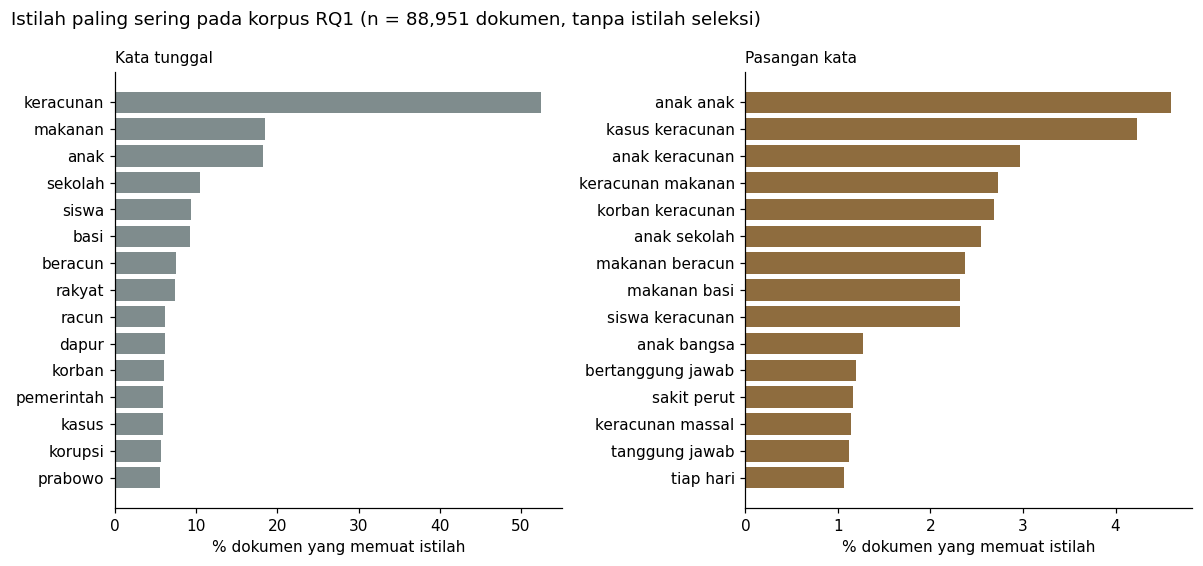

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, data, judul, warna in [(axes[0], uni, "Kata tunggal", "#7f8c8d"), (axes[1], bi, "Pasangan kata", "#8e6c3e")]:
    d = data.head(15).iloc[::-1]
    ax.barh(d["istilah"], d["persen_dokumen"], color=warna)
    ax.set_xlabel("% dokumen yang memuat istilah")
    ax.set_title(judul, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Istilah paling sering pada korpus RQ1 (n = {len(korpus):,} dokumen, tanpa istilah seleksi)",
             x=0.01, ha="left")
fig.tight_layout()
savefig("03_istilah_teratas.png")

RINGKASAN["konten"] = {
    "n_korpus": int(len(korpus)),
    "kata_tunggal_top10": uni.head(10).to_dict(orient="records"),
    "pasangan_kata_top10": bi.head(10).to_dict(orient="records"),
    "kata_tunggal_top10_per_platform": {p: t.to_dict(orient="records") for p, t in uni_pf.items()},
}

# 6. Pola Interaksi (Jumlah Suka)

Jumlah suka pada dokumen relevan selain video (komentar, balasan, unggahan, kutipan). Distribusi jumlah suka sangat menceng ke kanan, sehingga yang dilaporkan adalah median dan persentil, bukan rata-rata. Konsentrasi interaksi diukur dengan porsi total suka yang diterima 1% dokumen dengan suka terbanyak.

Catatan: jumlah suka adalah nilai pada saat pengumpulan data, sehingga dokumen lama punya waktu lebih panjang untuk mengumpulkan suka.

In [22]:
def ringkas_suka(g):
    s = g["like_count"].sort_values(ascending=False)
    k = max(1, int(np.ceil(len(s) * 0.01)))
    total = s.sum()
    return pd.Series({
        "dokumen": len(s),
        "median": s.median(),
        "p90": s.quantile(0.90),
        "p99": s.quantile(0.99),
        "maks": s.max(),
        "rata_rata": round(s.mean(), 2),
        "persen_tanpa_suka": round(100 * (s == 0).mean(), 1),
        "persen_suka_dari_1pct_teratas": round(100 * s.iloc[:k].sum() / total, 1) if total else np.nan,
    })

suka = nonvideo_rel.groupby("platform").apply(ringkas_suka)
suka_jenis = nonvideo_rel.groupby(["platform", "doc_type"]).apply(ringkas_suka)
suka.to_csv(OUT / "07_ringkasan_suka_per_platform.csv")
suka_jenis.to_csv(OUT / "08_ringkasan_suka_per_jenis.csv")
display(suka)
display(suka_jenis)
RINGKASAN["suka_per_platform"] = suka.reset_index().to_dict(orient="records")

,dokumen,median,p90,p99,maks,rata_rata,persen_tanpa_suka,persen_suka_dari_1pct_teratas
platform,,,,,,,,
X,14508.0,7.0,242.3,8982.9,119734.0,389.97,6.7,60.3
YouTube,80428.0,0.0,2.0,16.0,855.0,0.99,79.4,49.1


dokumen  median    p90       p99      maks  rata_rata  persen_tanpa_suka  persen_suka_dari_1pct_teratas
platform doc_type                                                                                                         
X        post       7170.0     9.0  366.2  14182.68  119734.0     571.76               12.0                           55.9
         quote      1817.0     8.0  522.2  16621.44   34934.0     586.68                0.1                           44.3
         reply      5521.0     5.0  105.0   1647.60   26473.0      89.15                2.0                           48.4
YouTube  comment   71958.0     0.0    1.0     17.00     855.0       1.02               80.6                           51.0
         reply      8470.0     0.0    2.0      9.00      78.0       0.74               69.2                           23.6

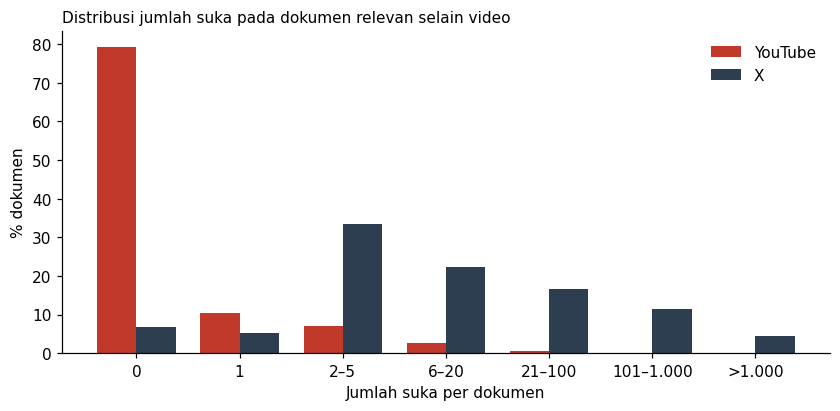

In [23]:
BINS = [-1, 0, 1, 5, 20, 100, 1000, np.inf]
LABELS = ["0", "1", "2–5", "6–20", "21–100", "101–1.000", ">1.000"]
kelas = (nonvideo_rel.assign(kelas=pd.cut(nonvideo_rel["like_count"], BINS, labels=LABELS))
         .groupby(["platform", "kelas"], observed=False).size().unstack(0, fill_value=0))
kelas = 100 * kelas / kelas.sum()
kelas.to_csv(OUT / "09_distribusi_kelas_suka.csv")

fig, ax = plt.subplots(figsize=(9, 3.8))
lebar = 0.38
x = np.arange(len(LABELS))
for i, p in enumerate(platforms):
    ax.bar(x + (i - (len(platforms) - 1) / 2) * lebar, kelas[p], lebar, label=p, color=PLATFORM_COLOR[p])
ax.set_xticks(x, LABELS)
ax.set_xlabel("Jumlah suka per dokumen")
ax.set_ylabel("% dokumen")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Distribusi jumlah suka pada dokumen relevan selain video", loc="left", fontsize=10)
savefig("04_distribusi_suka.png")

# 7. Simpan Ringkasan

In [24]:
with open(OUT / "ringkasan_deskriptif.json", "w", encoding="utf-8") as f:
    json.dump(RINGKASAN, f, ensure_ascii=False, indent=2, default=str)
print("Tersimpan:", OUT / "ringkasan_deskriptif.json")
print("Isi folder hasil:", sorted(p.name for p in OUT.rglob("*") if p.is_file()))

Tersimpan: /Users/mine/Documents/mbg-social-analytics/analysis/deskriptif/hasil/ringkasan_deskriptif.json
Isi folder hasil: ['01_jumlah_dokumen_per_tahap.csv', '01_volume_mingguan.png', '02_heatmap_hari_jam.png', '02_profil_penulis_konteks.csv', '03_istilah_teratas.png', '03_volume_mingguan.csv', '04_distribusi_suka.png', '04_minggu_puncak.csv', '05_kata_tunggal_teratas.csv', '06_pasangan_kata_teratas.csv', '07_ringkasan_suka_per_platform.csv', '08_ringkasan_suka_per_jenis.csv', '09_distribusi_kelas_suka.csv', 'ringkasan_deskriptif.json']
